In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cyclical_MCMC import load_fn, load_data
from convergence import print_conv_table, convergence_V
from plotting import plot_distributions, plot_VYconv

# 1. Load data and draws

In [3]:
Y, dY, dY_pd, Y_indx, T, VIX_df = load_data('data/SP500.csv', VIX_path='data/VIXCLS.csv')
Delta = 1
draws = load_fn('saved/draws')

Data from 2016-09-19 00:00:00 to 2026-09-17 00:00:00


In [4]:
N = 8
G = 50_000
burnin = 10_000
thin_V = 10


# 2. Table 1

In [5]:
print_conv_table(draws)

Parameter   Posterior Mean        s.e.        2.5%       97.5%        Skew        Kurt      Rhat       n_eff             B             W
----------------------------------------------------------------------------------------------------------------------------------------
mu                 0.04370     0.01374     0.01673     0.07063      0.0030      0.0003    1.0021        2442       0.01621       0.00019
kappa              0.03064     0.00511     0.02108     0.04110      0.1825      0.0619    1.0081        1024       0.00841       0.00003
theta              1.10192     0.14790     0.85731     1.43652      0.7370      1.2547    1.0035        1781       3.08273       0.02172
sigma_sq_V         0.04850     0.00556     0.03846     0.06018      0.2833      0.0334    1.0118         612       0.01434       0.00003
rho               -0.67603     0.04463    -0.75775    -0.58326      0.2615      0.0788    1.0076         746       0.59975       0.00196


In [6]:
V_Rhat, V_ESS = convergence_V(draws)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

# Marginal Distributions

In [7]:
xlim_dict = {
    #(0,1):[1,6],
    #(0,2):[0.025,0.09],
    #(1,0):[-0.8,-0.5],
    #(1,1):[-0.01,0.15]
}

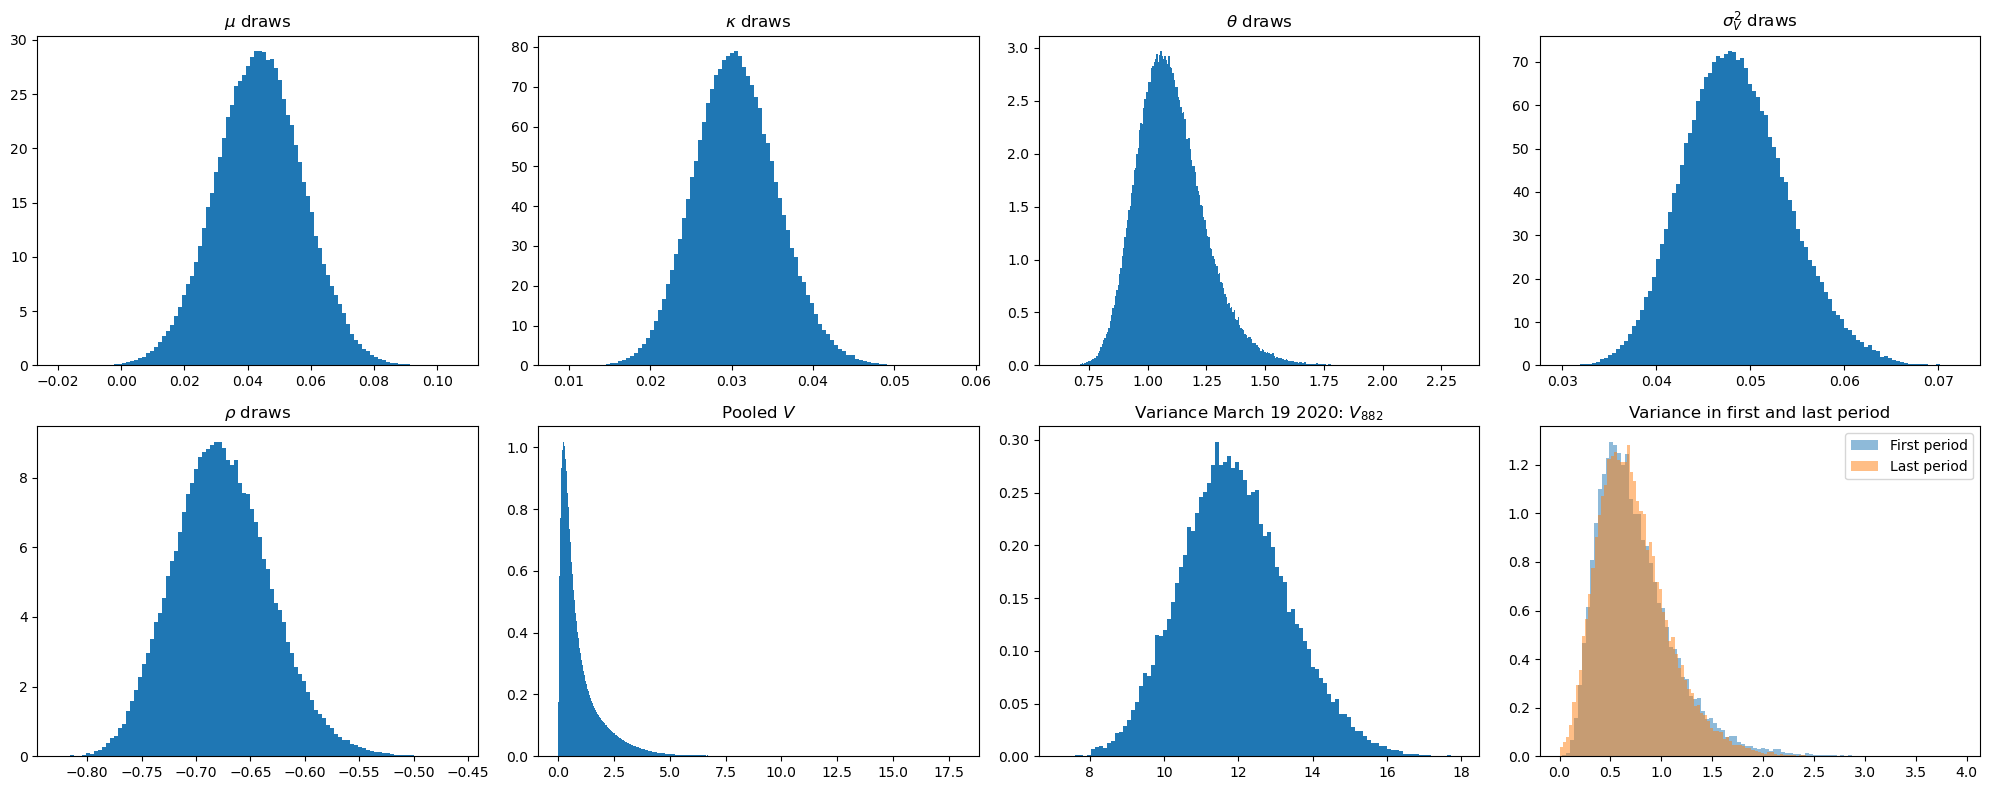

In [8]:
plot_distributions(draws, xlim_dict=xlim_dict, bins_=[100, 100, 300, 100, 100, 1000, 100, 100])

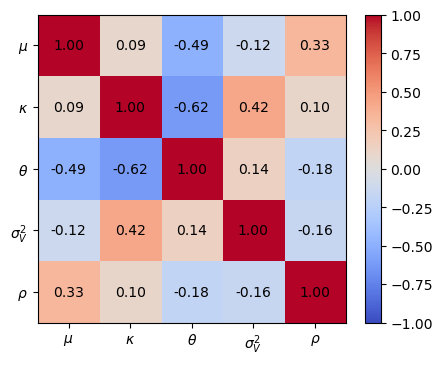

In [9]:
# construct df
pars = pd.DataFrame({
    'mu':         draws.mu.flatten(),
    'kappa':      draws.kappa.flatten(),
    'theta':      draws.kappatheta.flatten()/draws.kappa.flatten(),
    'sigma_sq_V': draws.sigma_sq_V.flatten(),
    'rho':        draws.rho.flatten(),
})

# compute all correlations
corr = pars.corr()

# pd.plotting.scatter_matrix(pars, figsize=(8, 8),
#                            alpha=0.1, diagonal='hist', hist_kwds={'bins': 100});

labels = [r'$\mu$', r'$\kappa$', r'$\theta$', r'$\sigma_V^2$', r'$\rho$']

f, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(5)); ax.set_xticklabels(labels)
ax.set_yticks(range(5)); ax.set_yticklabels(labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
f.colorbar(im)

# 2. Estimated Time Series of Variance

In [10]:
market_stress = [
    ['COVID-19 onset\nFeb 24 - May 5, 2020', '2020-02-24', '2020-05-04', 'red', (5,0.5)],
    ['FED rate hikes\nOct 2018 - Jan 2019', '2018-10-01', '2019-01-01', 'olive', (-3,0.5)]
]

vlines_stress = [
    ['Trump Tariffs\nApr 2, 2025', '2025-04-02', 'green', (200,0.5)],
    ['Russian Invasion of Ukraine\nMar 22, 2022', '2022-03-22', 'purple', (350,0.5)]
]

ylim = [-0.5,17.5]

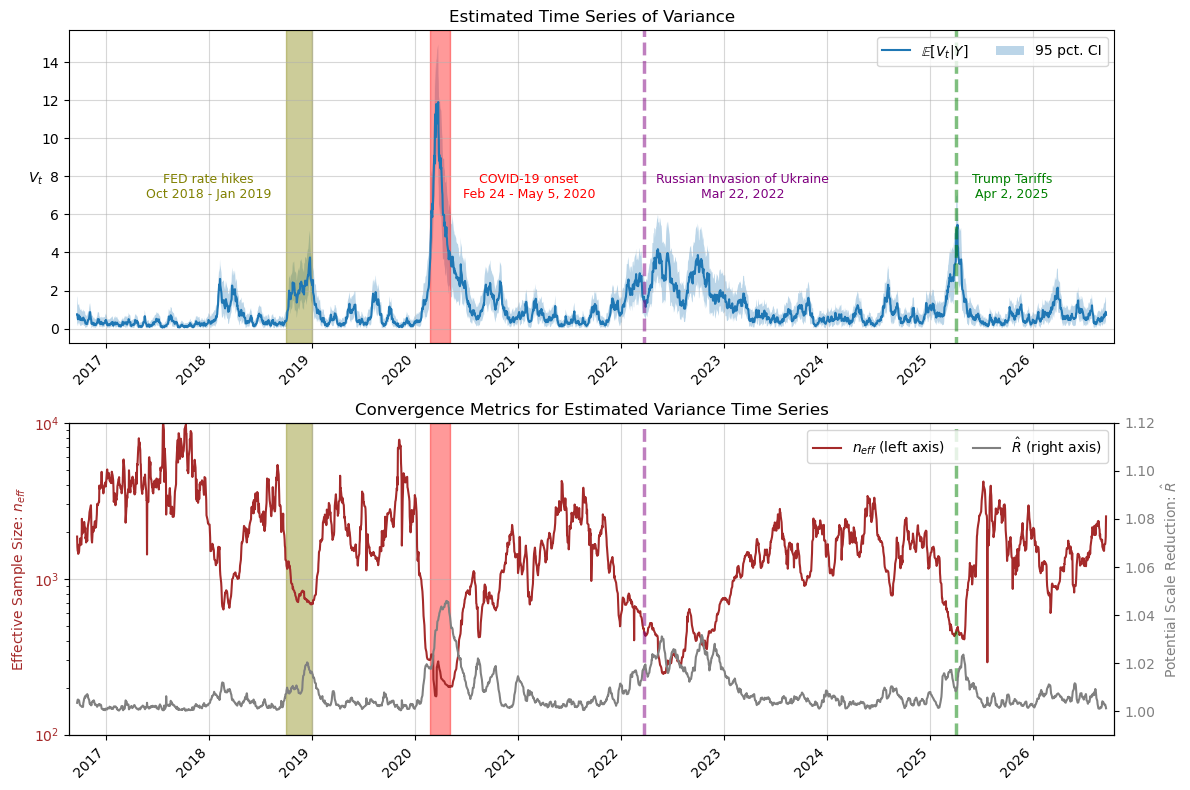

In [11]:
plot_VYconv(draws, V_Rhat, V_ESS, Y_indx, marked_intervals=market_stress, vlines=vlines_stress, filename='EstVTimeSeries')

In [12]:
V_max = np.array([draws.V[:,t,:].flatten().mean() for t in range(draws.V.shape[1])]).max()
V_max_date = np.array([draws.V[:,t,:].flatten().mean() for t in range(draws.V.shape[1])]).argmax()

scd_half = draws.V.shape[1] // 2
V_max_postCOVID = np.array([draws.V[:,t,:].flatten().mean() for t in range(scd_half, draws.V.shape[1])]).max()
V_max_postCOVID_date = scd_half + np.array([draws.V[:,t,:].flatten().mean() for t in range(scd_half, draws.V.shape[1])]).argmax()

print(f'V peaks at {V_max:.5f} at date {Y_indx[V_max_date]}')
print(f'Post-COVID peak is {V_max_postCOVID:.5f} at date {Y_indx[V_max_postCOVID_date]}')

V peaks at 11.90487 at date 2020-03-23 00:00:00
Post-COVID peak is 5.45372 at date 2025-04-08 00:00:00


In [13]:
print(f'ESS is between {V_ESS.min():.3f} and {V_ESS.max():.3f}')
print(f'Rhat is between {V_Rhat.min():.6f} and {V_Rhat.max():.6f}')

ESS is between 175.875 and 10230.403
Rhat is between 1.000205 and 1.045915


# 3. Estimated Innovations

In [14]:
from ll import eps_V_t, eps_Y_t

In [15]:
s  = slice(None, None, thin_V)
mu = draws.mu[:, None, s]
kappa = draws.kappa[:, None, s]
kappatheta = draws.kappatheta[:, None, s] #/ draws.kappa[:, None, s]
sigma_sq_V = draws.sigma_sq_V[:, None, s]
rho = draws.rho[:, None, s]
V  = draws.V

eps_V = eps_V_t(kappa, kappatheta, sigma_sq_V, V[:,:-1], V[:,1:], Delta)
eps_Y = eps_Y_t(mu, Y[None,:-1,None], Y[None,1:,None], V[:,:-1], Delta)

In [33]:
from scipy.stats import norm

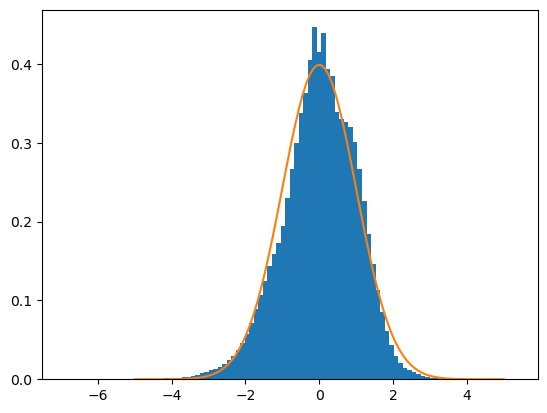

In [36]:
plt.hist(eps_Y.flatten(), bins=100, density=True)
plt.plot(np.linspace(-5,5, 100), norm.pdf(np.linspace(-5,5, 100)))

# Posterior Distribution of $\rho,\sigma^2_V$

In [16]:
x = draws.rho.flatten()
y = draws.sigma_sq_V.flatten()

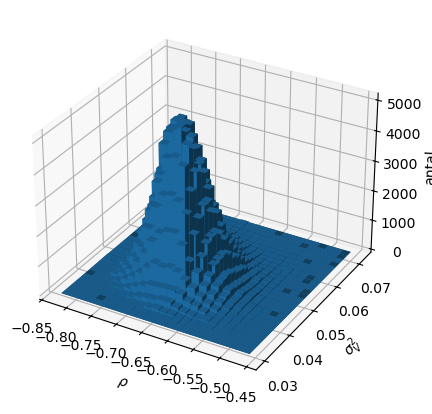

In [17]:
H, xedges, yedges = np.histogram2d(x, y, bins=25)

# søjlernes nederste hjørne og størrelse
xpos, ypos = np.meshgrid(xedges[:-1], yedges[:-1], indexing='ij')
xpos, ypos = xpos.ravel(), ypos.ravel()
dx = np.diff(xedges)[0]
dy = np.diff(yedges)[0]
dz = H.ravel()

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection='3d')
ax.bar3d(xpos, ypos, np.zeros_like(dz), dx, dy, dz, shade=True)
ax.set_xlabel(r'$\rho$')
ax.set_ylabel(r'$\sigma_V^2$')
ax.set_zlabel('antal')
plt.show()

# Trace plots

TypeError: 'types.SimpleNamespace' object is not subscriptable

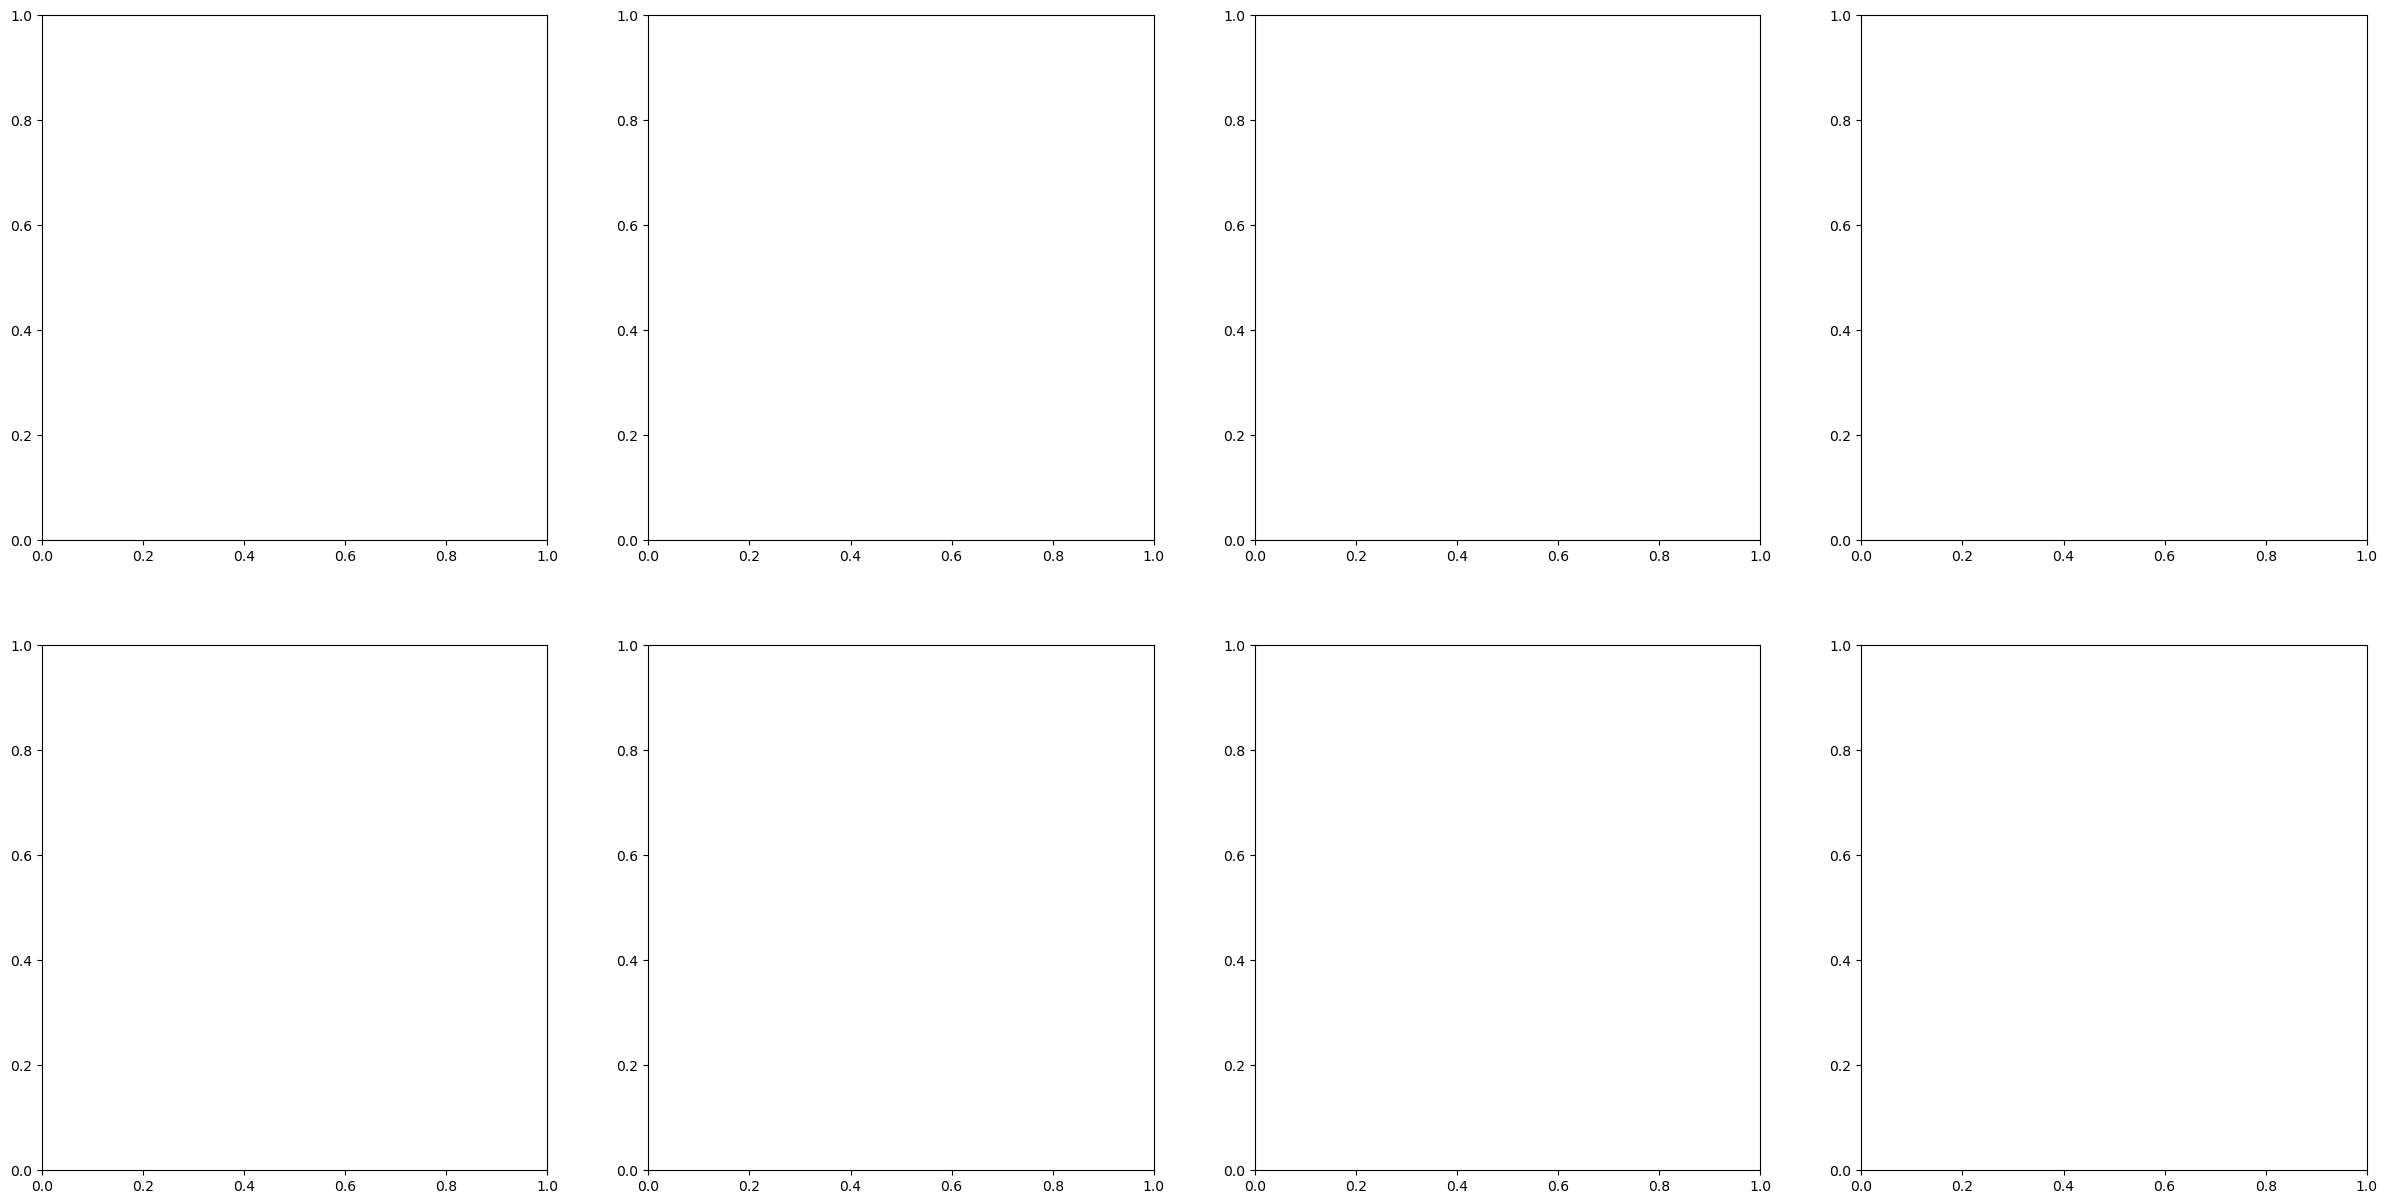

In [18]:
f, ax = plt.subplots(2,4, figsize=(30,15))

ax[0,0].plot(draws['mu_draws'][burnin:])
ax[0,0].set_title(r'$\mu$', fontsize=20)

ax[0,1].plot(draws['kappa_draws'][burnin:])
ax[0,1].set_title(r'$\kappa$', fontsize=20)

ax[0,2].plot(draws['kappatheta_draws'][burnin:])
ax[0,2].set_title(r'$\kappa \theta$', fontsize=20)

ax[0,3].plot(draws['sigma_sq_V_draws'][burnin:])
ax[0,3].set_title(r'$\sigma^2_V$', fontsize=20)

ax[1,0].plot(draws['rho_draws'][burnin:])
ax[1,0].set_title(r'$\rho$', fontsize=20)

ax[1,1].plot(draws['V_draws'][burnin:].mean(axis=0))
ax[1,1].set_title(r'Average $V_t$', fontsize=20)
# V_lo, V_hi = np.percentile(draws['V_draws'][burnin:], [2.5, 97.5], axis=0)
# ax[1,1].fill_between(np.arange(len(V_lo)), V_lo, V_hi, alpha=0.5, label='95 pct. band')

ax[1,2].plot(draws['V_draws'][882, burnin:])
ax[1,2].set_title(r'Variance at March 19th, 2020', fontsize=20)

random_period = 701
ax[1,3].plot(draws['V_draws'][random_period, burnin:])
ax[1,3].set_title(r'Variance at July 3th, 2020', fontsize=20)

In [ ]:
SP500_df.index[random_period]

Timestamp('2019-07-03 00:00:00')

# Acceptance rates

In [ ]:
V_intervals = ([None, 500,], [500, 1000], [1000, 1500], [1500, 2000], [2000, None])

In [ ]:
cum_acceptrate_rho = np.cumsum(accepts['rho']) / np.arange(1,1+len(accepts['rho']))
cum_acceptrate_sigma_sq_V = np.cumsum(accepts['sigma_sq_V']) / np.arange(1,1+len(accepts['sigma_sq_V']))

cum_acceptrates_V = np.zeros_like(accepts['V']) + np.nan
for row in range(accepts['V'].shape[0]):
    cum_acceptrates_V[row] = np.cumsum(accepts['V'][row]) / np.arange(1,1+len(accepts['V'][row]))

cum_acceptrates_V_mean = cum_acceptrates_V.mean(axis=0)
cum_acceptrates_V_lo, cum_acceptrates_V_hi = np.percentile(cum_acceptrates_V, [2.5, 97.5], axis=0)
cum_acceptrates_V_min, cum_acceptrates_V_max = np.percentile(cum_acceptrates_V, [0.0, 100], axis=0)

f, ax = plt.subplots()

ax.plot(cum_acceptrate_rho[burnin:], label=r'$\rho$')
ax.plot(cum_acceptrate_sigma_sq_V[burnin:], label=r'$\sigma^2_V$')
ax.plot(cum_acceptrates_V_mean[burnin:], color='black', ls='--', label=r'Average for $\{V_t \}_{t=1}^{T}$')
ax.fill_between(np.arange(len(cum_acceptrates_V_mean[burnin:])), cum_acceptrates_V_min[burnin:], cum_acceptrates_V_max[burnin:],
                 alpha=0.3, color='gray', label=r'min-max bounds for $\{V_t \}_{t=1}^{T}$')
ax.fill_between(np.arange(len(cum_acceptrates_V_mean[burnin:])), cum_acceptrates_V_lo[burnin:], cum_acceptrates_V_hi[burnin:],
                 alpha=0.3, color='blue', label=r'95 pct. bounds for $\{V_t \}_{t=1}^{T}$')
ax.set_xlabel('Cycle')
ax.set_ylabel('Cumulative Average Acceptance Rate')
ax.grid()

ax.legend();

KeyboardInterrupt: 